# Salary Prediction

## Objective

The objective of this notebook is to build machine learning models that predict the average annual salary of data-related jobs based on job characteristics and technical skills extracted from job description.

The models are also used to identify the factors that have the greatest influence on salary prediction.

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import RandomizedSearchCV

### Load Processed Dataset

Load the processed dataset containing the cleaned job information and the technical skill features extracted in the previous notebook.

In [70]:
df = pd.read_csv('../data/processed/feature_engineered.csv')

In [71]:
df.columns

Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'Easy Apply', 'Min Salary (K)', 'Max Salary (K)', 'Average Salary (K)',
       'Average Employee Size', 'Job Category', 'Seniority',
       'Is Core Data Role', 'sql', 'python', 'statistics', 'machine learning',
       'data analysis', 'big data', 'data analytics', 'business intelligence',
       'data visualization', 'data mining', 'data pipelines',
       'data engineering', 'data management', 'data modeling', 'deep learning',
       'software development', 'statistical analysis', 'advanced analytics',
       'natural language processing'],
      dtype='object')

### Filter Core Data Roles

The dataset contains both data-related and non-data-related job postings.

Since the objective of this project is to predict salaries for data professionals, only core data roles are retained for modeling.

Non-data-related positions are removed to make the prediction task more consistent and interpretable.

In [72]:
df_data_core = df[df['Is Core Data Role']].copy()

In [73]:
df_data_core.shape

(3829, 41)

### Define Target Variable

The target variable is the average annual salary.

In [74]:
target = 'Average Salary (K)'

X = df_data_core.drop(target, axis=1)
y = df_data_core[target]

In [75]:
X.columns

Index(['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
       'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'Easy Apply', 'Min Salary (K)', 'Max Salary (K)',
       'Average Employee Size', 'Job Category', 'Seniority',
       'Is Core Data Role', 'sql', 'python', 'statistics', 'machine learning',
       'data analysis', 'big data', 'data analytics', 'business intelligence',
       'data visualization', 'data mining', 'data pipelines',
       'data engineering', 'data management', 'data modeling', 'deep learning',
       'software development', 'statistical analysis', 'advanced analytics',
       'natural language processing'],
      dtype='object')

In [76]:
y.sample(5)

842     136
3402    106
2830    136
1163     86
3795     73
Name: Average Salary (K), dtype: int64

### Remove Unnecessary Features

Some columns are plain text or contain direct information about average salary so they are not useful for modeling therefore they are removed.

In [77]:
remove_columns = [
    'Is Core Data Role',
    'Min Salary (K)',
    'Max Salary (K)',
    'Salary Estimate',
    'Job Description',
    'Job Title',
    'Company Name',
    'Size'
]

In [78]:
X = X.drop(remove_columns, axis=1)

In [79]:
X.columns

Index(['Rating', 'Location', 'Headquarters', 'Founded', 'Type of ownership',
       'Industry', 'Sector', 'Revenue', 'Competitors', 'Easy Apply',
       'Average Employee Size', 'Job Category', 'Seniority', 'sql', 'python',
       'statistics', 'machine learning', 'data analysis', 'big data',
       'data analytics', 'business intelligence', 'data visualization',
       'data mining', 'data pipelines', 'data engineering', 'data management',
       'data modeling', 'deep learning', 'software development',
       'statistical analysis', 'advanced analytics',
       'natural language processing'],
      dtype='object')

### Check Missing Value

Missing values are examined before preprocessing.

Columns with excessive missing values will be reviewed and either removed or handled during preprocessing.

In [80]:
X.isna().sum().sort_values(ascending=False)

Easy Apply                     3668
Competitors                    2715
Founded                         962
Industry                        537
Sector                          537
Rating                          400
Average Employee Size           298
Headquarters                    233
Type of ownership               222
Revenue                         222
Location                          0
Job Category                      0
Seniority                         0
sql                               0
python                            0
statistics                        0
machine learning                  0
data analysis                     0
big data                          0
data analytics                    0
business intelligence             0
data visualization                0
data mining                       0
data pipelines                    0
data engineering                  0
data management                   0
data modeling                     0
deep learning               

In [81]:
X = X.drop(['Easy Apply', 'Competitors'], axis=1)

### Create Company Age Feature

The founding year of a company will be transformed into company age.

Since the dataset was collected around 2020, it is used as the reference year to calculate company age.

Company Age = 2020 - Founded

In [82]:
reference_year = 2020
X['Company Age'] = reference_year - X['Founded']

In [83]:
X[['Founded', 'Company Age']].head()

,Founded,Company Age
0,2007.0,13.0
1,2008.0,12.0
2,NaN,NaN
3,2019.0,1.0
4,2007.0,13.0


In [84]:
X = X.drop('Founded', axis=1)

### Identify Feature Types

The dataset contains different preprocessing steps.

- Numerical features
- Categorical features
- Binary features

In [85]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3829 entries, 0 to 3908
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Rating                       3429 non-null   float64
 1   Location                     3829 non-null   object 
 2   Headquarters                 3596 non-null   object 
 3   Type of ownership            3607 non-null   object 
 4   Industry                     3292 non-null   object 
 5   Sector                       3292 non-null   object 
 6   Revenue                      3607 non-null   object 
 7   Average Employee Size        3531 non-null   float64
 8   Job Category                 3829 non-null   object 
 9   Seniority                    3829 non-null   object 
 10  sql                          3829 non-null   bool   
 11  python                       3829 non-null   bool   
 12  statistics                   3829 non-null   bool   
 13  machine learning       

In [86]:
numerical_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()
binary_features = X.select_dtypes(include='bool').columns.tolist()

In [87]:
print('Numerical')
print(numerical_features)
print()
print('Categorical')
print(categorical_features)
print()
print('Binary')
print(binary_features)
print()

Numerical
['Rating', 'Average Employee Size', 'Company Age']

Categorical
['Location', 'Headquarters', 'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Job Category', 'Seniority']

Binary
['sql', 'python', 'statistics', 'machine learning', 'data analysis', 'big data', 'data analytics', 'business intelligence', 'data visualization', 'data mining', 'data pipelines', 'data engineering', 'data management', 'data modeling', 'deep learning', 'software development', 'statistical analysis', 'advanced analytics', 'natural language processing']



### Encode Binary skill Features

Technical skills are currently stored as boolean values.

They are converted into numerical binary features:
- True: 1
- False: 0

This representation is suitable for machine learning algorithms.

In [88]:
X[binary_features] = X[binary_features].astype(int)

In [89]:
X[binary_features].head()

,sql,python,statistics,machine learning,data analysis,big data,data analytics,business intelligence,data visualization,data mining,data pipelines,data engineering,data management,data modeling,deep learning,software development,statistical analysis,advanced analytics,natural language processing
0,1,0,1,1,0,1,0,1,1,1,0,0,0,0,0,0,0,0,0
1,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1,1,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0
4,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


## Create Preprocessing Pipelines

Different preprocessing steps are applied to different feature groups.

Numerical features:
- Missing values are replaced using the median.
- Features are scaled using StandardScaler.

Categorical features:
- Missing values are replaced using 'Unknown'.
- Categories are transformed using OneHot Encoding.

Binary Skill features:
- Already converted into numerical 0/1 values and passed directly to the model.

In [90]:
numerical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [91]:
categorical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [92]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_pipeline, numerical_features),
        ('categorical', categorical_pipeline, categorical_features),
        ('binary', 'passthrough', binary_features),
    ]
)

### Split Data

The dataset is divided into training and testing sets.

The training set is used to learn patterns from the data, while the test set is used to evaluate how well the model performs on unseen job postings.

20% of the data is reserved for testing.

In [93]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Baseline Model: Linear Regression

Linear Regression is used as a baseline model.

It provides a simple reference point to understand how well salary can be predicted using a linear relationship between job features and salary.

In [94]:
linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

In [95]:
linear_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Check for Overfitting / Underfitting

In [96]:
print('Accuracy on train data:', linear_model.score(X_train, y_train))
print('Accuracy on test data:', linear_model.score(X_test, y_test))

Accuracy on train data: 0.548785928512773
Accuracy on test data: 0.1446516165897448


**Report: Underfitting detected**

This model performs poorly on training data. This indicates that we need to use a more complicated model.

## Lasso Regressor

In [97]:
lasso_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', Lasso(random_state=42))
    ]
)

In [98]:
lasso_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Check for Overfitting / Underfitting

In [99]:
print('Accuracy on train data:', lasso_model.score(X_train, y_train))
print('Accuracy on test data:', lasso_model.score(X_test, y_test))

Accuracy on train data: 0.13012457542152311
Accuracy on test data: 0.12079810766777954


**Report: Underfitting detected**

This model performs poorly on training data. This indicates that we need to use a more complicated model.

## Decision Tree Regressor

In [100]:
dt_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(random_state=42))
    ]
)

In [101]:
dt_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Check for Overfitting / Underfitting

In [102]:
print('Accuracy on train data:', dt_model.score(X_train, y_train))
print('Accuracy on test data:', dt_model.score(X_test, y_test))

Accuracy on train data: 0.9657932487940863
Accuracy on test data: -0.11845958210287932


**Report: Overfitting detected**

The decision tree model performs very well on training data but extremely poorly on test data.

In [103]:
y_pred = linear_model.predict(X_test)

## Random Forest Regressor

Random Forest is an ensemble learning algorithm that combines multiple decision trees.

Unlike linear models, it can capture complex and non-linear relationships between job characteristics and salary.

In [104]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(random_state=42))
    ]
)

In [105]:
rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Check for Overfitting / Underfitting

In [106]:
print('Accuracy on train data:', rf_model.score(X_train, y_train))
print('Accuracy on test data:', rf_model.score(X_test, y_test))

Accuracy on train data: 0.8781312899058215
Accuracy on test data: 0.3063630190799532


**Report**

The performance of random forest regressor is acceptable on training data but still not enough on test data.

## Support Vector Regressor

In [107]:
svr_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', SVR())
    ]
)

In [108]:
svr_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Check for Overfitting / Underfitting

In [109]:
print('Accuracy on train data:', svr_model.score(X_train, y_train))
print('Accuracy on test data:', svr_model.score(X_test, y_test))

Accuracy on train data: 0.1491729011792018
Accuracy on test data: 0.1137911075359227


**Report: Underfitting detected**

The SVR model performs extremely poorly on training data.

### Report

The best perfoming model so far is random forest regressor. 

Further model evaluation and hyperparameter tuning will be done on random forest regressor.

### Random Forest Regressor Evaluation

The model is evaluated using:

- MAE: Average absolute difference between predicted and actual salary.
- RMSE: Penalizes larger prediction errors.
- R2: Measures how much variance in salary is explained by the model.

In [110]:
y_pred = rf_model.predict(X_test)

In [111]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

In [112]:
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2: {r2:.2f}')

MAE: 24.42
RMSE: 31.54
R2: 0.31


### Hyperparameter Tuning

The default Random Forest model is optimized using RandomSearchCV.

Different combinations of hyperparameters are evaluated using cross-validation to improve the model's predictive performance while reducing overfitting.

Randomized Search is used with 5-fold cross-validation to search for a better combination of Random Forest hyperparameter.

The best model is selected based on the lowest prediction error across the validation folds.

In [113]:
param_grid = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

In [114]:
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=42
)

In [116]:
random_search.fit(X_train, y_train);

In [117]:
random_search.best_params_

{'model__n_estimators': 200,
 'model__min_samples_split': 10,
 'model__min_samples_leaf': 1,
 'model__max_features': 'sqrt',
 'model__max_depth': None}

In [118]:
random_search.best_score_

np.float64(-1054.000946761381)

In [119]:
best_rf = random_search.best_estimator_

In [120]:
y_pred_best = best_rf.predict(X_test)

In [121]:
mae = mean_absolute_error(y_test, y_pred_best)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_best))
r2 = r2_score(y_test, y_pred_best)

In [122]:
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2: {r2:.2f}')

MAE: 25.46
RMSE: 31.68
R2: 0.30


### Hyperparameter Tuning Results

Although the tuned model achieved competitive performance during cross-validation, it did not outperform the default Random Forest model on the test set.

Therefore, the default Random Forest model was selected as the final model for further interpretation.

### Feature Importance

Feature importance is used to identify which variables contributed the most to the Random Forest predictions.

The importance scores indicates how much each feature helped reduce prediction error across all decision trees.

Since the predictive performance of the model is moderate, the importance of the model is moderate, the importance values should be interpreted as model-specific insights rather than definitive evidence of casual relationships.

In [123]:
rf_importance = rf_model.named_steps['model'].feature_importances_
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

In [124]:
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importance
})

In [125]:
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
feature_importance.head()

,Feature,Importance
813,categorical__Job Category_Data Scientist,0.055181
133,"categorical__Location_San Jose, CA",0.051291
2,numerical__Company Age,0.047392
0,numerical__Rating,0.039958
134,"categorical__Location_Santa Clara, CA",0.038196


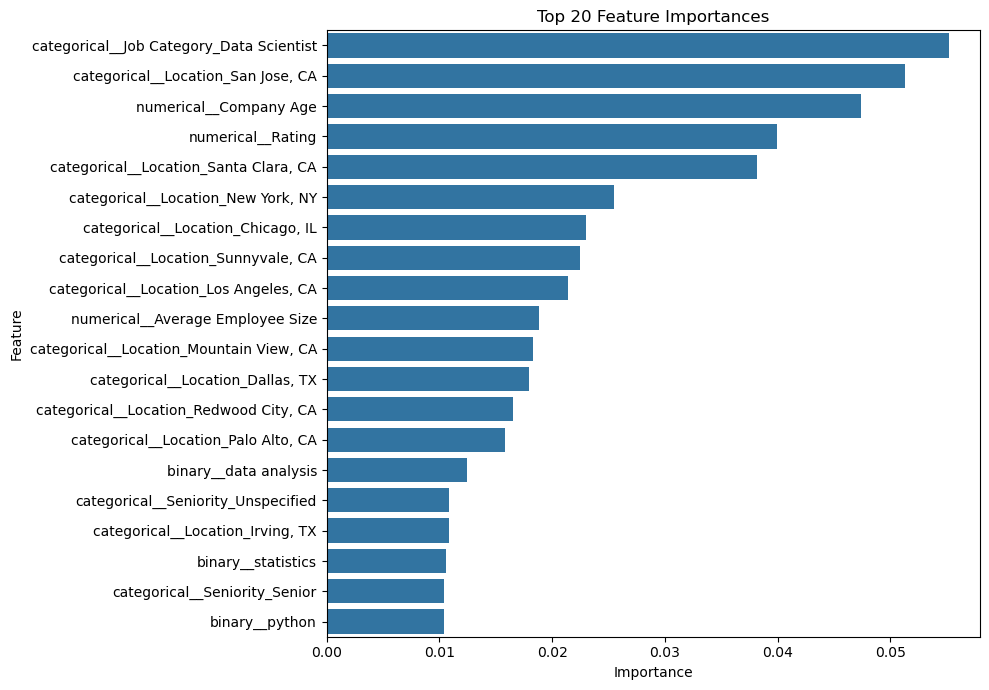

In [126]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(20),
    x='Importance',
    y='Feature'
)
plt.title('Top 20 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Model Evaluation and Interpretation

## Model Comparison

Three different approaches were evaluated for salary prediction:

- Linear Regression as a baseline model
- Random Forest Regressor
- Tuned Random Forest using RandomizedSearchCV

The models were compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

| Model | MAE (K) | RMSE (K) | R² |
|---|---:|---:|---:|
| Random Forest | 24.42 | 31.54 | 0.31 |
| Tuned Random Forest | 25.46 | 31.68 | 0.30 |


The Random Forest model achieved the best performance on the test set, reducing prediction error compared with the linear baseline.

Although hyperparameter tuning improved the model configuration, it did not improve performance on the test set. Therefore, the default Random Forest model was selected as the final model.

## Feature Importance Analysis

Feature importance was analyzed using the final Random Forest model to understand which variables contributed most to salary predictions.

The most influential features were:

1. Job Category (especially Data Scientist)
2. Location-related features
3. Company Age
4. Company Rating
5. Technical skills such as data analysis, statistics, Python, and SQL

Location and job category had a stronger contribution than individual technical skills.

This suggests that salary differences in data-related roles are influenced not only by technical requirements but also by job type and geographic market conditions.

## Limitations

The final model achieved an R² score of approximately 0.30, meaning that a significant portion of salary variation remains unexplained.

Possible reasons include:

- Missing information about years of experience
- Lack of detailed job level information
- Limited skill extraction from job descriptions
- Company-specific compensation factors
- Market conditions not captured in the dataset

Therefore, feature importance results should be interpreted as model-based patterns rather than causal relationships.